# Estudios de ablación: Tarea 2 - Microplásticos

En este cuaderno auxiliar se justifican las decisiones de implementación tomadas en la segunda tarea de la práctica. Se ha realizado un estudio de ablación para cada solución planteada, justificando así la utilidad de las opciones mantenidas.

## Organización

Para llevar a cabo el estudio, se han realizado distintas funciones que admiten su reconfiguración a través de sus parámetros. Una vez implementadas estas funciones, se pueden ir probando de forma independiente cada una de las soluciones. Por ejemplo, para probar varios métodos de segmentación:

```python
distance_mask(img)                    # Comportamiento normal (usado en la práctica)
distance_mask(img, threshold=14)      # Comportamiento tras cambiar el umbral
distance_mask(img, space="rgb")       # Comportamiento tras cambiar el mapa de color
```

Para facilitar la realización de los distintos experimentos, se ha implementado la función `rules_experiment`, que realiza el _pipeline_ completo reenviando los cambios indicados a la función que los usa.
<br>
Para estos estudios solo se han utilizado las imágenes de entrenamiento, sobre las que se ha aplicado _data augmentation_. La imagen de _test_ únicamente se ha utilizado como comprobación final tras realizar todas las pruebas y elegir el _pipeline_ con mejores resultados. Al medir con las mismas imágenes con las que se _aprende_, el resultado es optimista, aunque es una buena medida orientativa para comparar distintas variantes.

## Índice

1. [Preparación](#1-preparación)
    - [1.1 Constantes y _data augmentation_](#11-constantes-y-data-augmentation)
    - [1.2 Imágenes de entrenamiento](#12-imágenes-de-entrenamiento)
    - [1.3 Segmentación](#13-segmentación)
    - [1.4 Caracterización de partículas](#14-caracterización-de-partículas)
    - [1.5 Reglas, evaluación y dibujo](#15-reglas-evaluación-y-dibujo)
2. [Pruebas](#2-pruebas)
    - [2.1 Segmentación](#21-segmentación)
        - [2.1.1 Espacios de color: Lab o RGB](#211-espacios-de-color-lab-o-rgb)
        - [2.1.2 Filtros de suavizado](#212-filtros-de-suavizado)
        - [2.1.3 Umbrales de separación](#213-umbrales-de-separación)
        - [2.1.4 Umbral adaptativo](#214-umbral-adaptativo)
        - [2.1.5 Margen en los bordes](#215-margen-en-los-bordes)
        - [2.1.6 Fondo con mediana o gaussiano](#216-fondo-con-mediana-o-gaussiano)
        - [2.1.7 Reducir las fotos de entrenamiento (`SCALE_TRAIN`)](#217-reducir-las-fotos-de-entrenamiento-scale_train)
    - [2.2 Características de las partículas](#22-características-de-las-partículas)
        - [2.2.1 Características geométricas de SMACC](#221-características-geométricas-de-smacc)
        - [2.2.2 Detección de TAR](#222-detección-de-tar)
        - [2.2.3 Detección de textura](#223-detección-de-textura)
        - [2.2.4 Detección de textura LBP](#224-detección-de-textura-lbp)
        - [2.2.5 `cv2.matchShapes`](#225-cv2matchshapes)
    - [2.3 Datos de entrenamiento](#23-datos-de-entrenamiento)
        - [2.3.1 _Data augmentation_](#231-data-augmentation)
        - [2.3.2 Reescalado como _data augmentation_](#232-reescalado-como-data-augmentation)
    - [2.4 Clasificador](#24-clasificador)
        - [2.4.1 Orden de las reglas](#241-orden-de-las-reglas)

## 1. Preparación

Reutilización del _pipeline_ de [`VC_P3.ipynb`](./VC_P3.ipynb), modificado para poder ajustar sus parámetros en cada experimento. 

### 1.1 Constantes y _data augmentation_

In [2]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import cross_val_predict, LeaveOneOut
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from skimage.feature import local_binary_pattern

TRAIN = {"FRA": "exercises/plastics/fragment-03-olympus-10-01-2020.JPG",
         "PEL": "exercises/plastics/pellet-03-olympus-10-01-2020.JPG",
         "TAR": "exercises/plastics/tar-03-olympus-10-01-2020.JPG"}

SCALE_TRAIN = 0.25
BG_KSIZE = 101
MIN_AREA, MAX_AREA = 40, 8000

DATA_AUGMENTATION = {
    "contrast":   (0.8, 1.2),
    "brightness": (-20, 20),
    "color_gain": (0.9, 1.1),
    "gamma":      (0.8, 1.25),
    "blur":       (0.01, 1.2),
    "noise":      (0, 4),
}

def random(name, size=None):
    return np.random.uniform(DATA_AUGMENTATION[name][0], DATA_AUGMENTATION[name][1], size)

def augment(img):
    img = img.astype(np.float32)

    img = cv2.GaussianBlur(img, (0, 0), random("blur"))
    img = img + np.random.normal(0, random("noise"), img.shape)
    img = img * random("contrast") + random("brightness")
    img = img * random("color_gain", 3)
    img = 255 * (np.clip(img, 0, 255) / 255) ** random("gamma")

    return img.astype(np.uint8)

### 1.2 Imágenes de entrenamiento

In [3]:
def load(path, scale=SCALE_TRAIN):
    return cv2.resize(cv2.imread(path), None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

def make_train_set(scale=SCALE_TRAIN, n_aug=5, seed=0):
    np.random.seed(seed)
    images = {}
    for label, path in TRAIN.items():
        img = load(path, scale)
        images[label] = [img] + [augment(img) for _ in range(n_aug)]
    return images

TRAIN_SET = make_train_set()

### 1.3 Segmentación

Detección de las partículas y su contorno:

In [4]:
def compute_background(img, kind="median"):
    if kind == "gauss":
        return cv2.GaussianBlur(img, (BG_KSIZE, BG_KSIZE), 0)
    return cv2.merge([cv2.medianBlur(channel, BG_KSIZE) for channel in cv2.split(img)])

def color_distance(img, bg):
    return np.sqrt(((img.astype(np.float32) - bg.astype(np.float32)) ** 2).sum(axis=-1))

def is_valid_particle(contour, shape, border=0.02):
    area = cv2.contourArea(contour)
    if not (MIN_AREA <= area <= MAX_AREA) or len(contour) < 5:
        return False

    margin = int(border * max(shape))
    x, y, w, h = cv2.boundingRect(contour)
    return x > margin and y > margin and \
           x + w < shape[1] - margin and y + h < shape[0] - margin

def smooth(img, kind="bilateral"):
    if kind == "bilateral":
        return cv2.bilateralFilter(img, 7, 40, 7)
    if kind == "gauss":
        return cv2.GaussianBlur(img, (5, 5), 0)
    return img

def distance_mask(img, space="lab", smoothing="bilateral", background="median", threshold=10):
    img = smooth(img, smoothing)
    if space == "lab":
        img = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    bg = compute_background(img, background)

    _, mask = cv2.threshold(color_distance(img, bg), threshold, 255, cv2.THRESH_BINARY)
    return mask

def segment(img, mask_fn=distance_mask, border=0.02, **segment_options):
    lab = cv2.cvtColor(cv2.bilateralFilter(img, 7, 40, 7), cv2.COLOR_BGR2LAB)
    bg = compute_background(lab)

    mask = mask_fn(img, **segment_options)
    mask = cv2.medianBlur(mask.astype(np.uint8), 3)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    particles = [c for c in contours if is_valid_particle(c, mask.shape, border)]
    return particles, lab, bg

### 1.4 Caracterización de partículas

Generación de las distintas _features_, geométricas y de color, para cada partícula:

In [ ]:
def centroid_distances(contour):
    moments = cv2.moments(contour)
    cx, cy = moments["m10"] / moments["m00"], moments["m01"] / moments["m00"]
    points = contour.reshape(-1, 2)
    return np.sqrt((points[:, 0] - cx) ** 2 + (points[:, 1] - cy) ** 2)

def shape_features(contour):
    x, y, w, h = cv2.boundingRect(contour)
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)
    _, axes, _ = cv2.fitEllipse(contour)
    distances = centroid_distances(contour)

    return {
        "x": x, "y": y, "w": w, "h": h,
        "area": area,
        "perimeter": perimeter,
        "circularity": 4 * np.pi * area / perimeter ** 2,
        "ellipse_ratio": min(axes) / max(axes),
        "dist_ratio": distances.min() / distances.max(),
        "area_bbox_ratio": area / (w * h),
        "aspect_ratio": min(w, h) / max(w, h),
    }

def color_features(contour, img_lab, bg):
    mask = np.zeros(img_lab.shape[:2], np.uint8)
    cv2.drawContours(mask, [contour], -1, 255, -1)

    particle = img_lab[mask > 0].astype(np.float32)
    background = bg[mask > 0].astype(np.float32)

    L_ratio = particle[:, 0].mean() / background[:, 0].mean()
    chroma_rel = color_distance(particle[:, 1:], background[:, 1:]).mean()

    return {"L_ratio": L_ratio, "chroma_rel": chroma_rel}

Combinación de todas las características de las partículas en un único _dataframe_:

In [6]:
def extract_particles(img, extra=None, **segment_options):
    contours, img_lab, bg = segment(img, **segment_options)
    rows = [{**shape_features(c), **color_features(c, img_lab, bg)} for c in contours]
    if extra:
        rows = [{**row, **extra(c, img)} for row, c in zip(rows, contours)]
    df = pd.DataFrame(rows)
    return df, contours

def particle_table(image_set, extra=None, **segment_options):
    rows = []
    for label, images in image_set.items():
        for k, img in enumerate(images):
            df, contours = extract_particles(img, extra, **segment_options)
            rows.append(df.assign(label=label, image=k, contour=contours))
    return pd.concat(rows, ignore_index=True)

### 1.5 Reglas, evaluación y dibujo

Reglas de clasificación y búsqueda de umbrales:

In [7]:
THRESHOLD_POSSIBILITIES = {
    "max_brightness": np.arange(0.30, 0.96, 0.05),
    "max_color": np.arange(2, 16, 1.0),
    "min_circularity": np.arange(0.70, 0.93, 0.01),
}

def predict(df, t):
    is_tar = (df["L_ratio"] < t["max_brightness"]) & (df["chroma_rel"] < t["max_color"])
    is_pel = df["circularity"] > t["min_circularity"]
    return np.select([is_tar, is_pel], ["TAR", "PEL"], default="FRA")

def all_threshold_combinations(possibilities):
    combinations = [{}]
    for name, values in possibilities.items():
        combinations = [{**c, name: v} for c in combinations for v in values]
    return combinations

def fit(df, predict_fn=predict, possibilities=THRESHOLD_POSSIBILITIES):
    all_thresholds = all_threshold_combinations(possibilities)
    scores = [balanced_accuracy_score(df["label"], predict_fn(df, t)) for t in all_thresholds]
    best = np.argmax(scores)
    return all_thresholds[best]

Ejecución de un experimento completo (segmentar, elegir los umbrales y clasificar) y cálculo de su acierto, global y por clase:

In [8]:
def class_scores(df, label):
    of_class = df[df["label"] == label]
    return {f"det{label}": len(of_class), f"acc{label}": (of_class["pred"] == label).mean()}

def scores(name, df):
    row = {"var": name, "accuracy": balanced_accuracy_score(df["label"], df["pred"])}
    for label in TRAIN:
        row.update(class_scores(df, label))
    return row

def result(name, df, y_pred, images=TRAIN_SET):
    df = df.assign(pred=y_pred)
    return {"row": scores(name, df), "df": df, "images": images}

def rules_experiment(name, images=TRAIN_SET, measure_on=None,
                     predict_fn=predict, possibilities=THRESHOLD_POSSIBILITIES,
                     extra=None, **segment_options):
    train = particle_table(images, extra, **segment_options)
    thresholds = fit(train, predict_fn, possibilities)

    if measure_on is None:
        return result(name, train, predict_fn(train, thresholds), images)

    measured = particle_table(measure_on, extra, **segment_options)
    return result(name, measured, predict_fn(measured, thresholds), measure_on)

Visualización de los resultados - tabla comparativa y detecciones sobre las fotos originales (verde = bien clasificada, rojo = mal clasificada):

           var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
Pipeline final     0.835     413   0.707     328   0.845     309   0.955


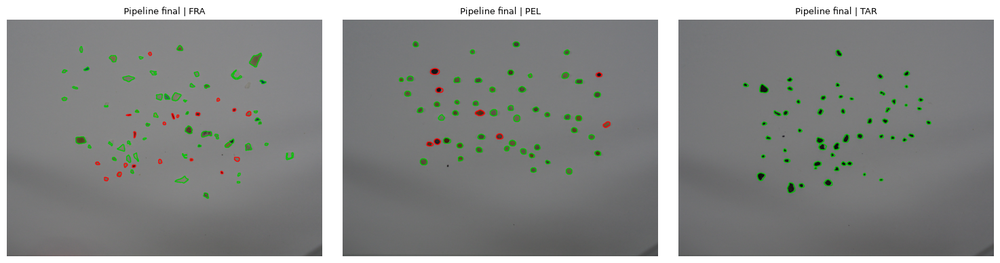

In [9]:
def draw_detections(img, particles):
    det_img = img.copy()
    for p in particles.itertuples():
        color = (0, 200, 0) if p.pred == p.label else (0, 0, 255)
        cv2.drawContours(det_img, [p.contour], -1, color, 2)
    return cv2.cvtColor(det_img, cv2.COLOR_BGR2RGB)

def original_particles(df, label):
    return df[(df["label"] == label) & (df["image"] == 0)]

def results_table(results):
    return pd.DataFrame([r["row"] for r in results]).round(3)

def plot_detections(results):
    plt.figure(figsize=(15, 3.8 * len(results)))
    for i, r in enumerate(results):
        for j, label in enumerate(TRAIN):
            plt.subplot(len(results), 3, 3 * i + j + 1)
            plt.imshow(draw_detections(r["images"][label][0], original_particles(r["df"], label)))
            plt.title(f"{r['row']['var']} | {label}", fontsize=9)
            plt.axis("off")
    plt.tight_layout()
    plt.show()

def renamed(result, name):
    return {**result, "row": {**result["row"], "var": name}}

def show(results):
    print(results_table(results).to_string(index=False))
    plot_detections(results)

FINAL = rules_experiment("Pipeline final")
show([FINAL])

## 2. Pruebas

### 2.1 Segmentación

Cada experimento muestra una tabla y una figura:

- **Tabla:** una fila por variante, con su acierto (`accuracy`, la media del acierto de las tres clases), el número de partículas detectadas de cada clase (`detFRA`, `detPEL`, `detTAR`) y la proporción de partículas de cada clase que se clasifican bien (`accFRA`, `accPEL`, `accTAR`).
- **Figura:** las detecciones de cada variante sobre las tres fotos originales, en verde si la partícula se clasifica bien y en rojo si se clasifica mal.

#### 2.1.1 Espacios de color: Lab o RGB

Compara el uso del mapa de color Lab o RGB como método de segmentación:

           var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
Lab, umbral 10     0.835     413   0.707     328   0.845     309   0.955
RGB, umbral 10     0.782     426   0.601     325   0.775     306   0.971
RGB, umbral 15     0.826     425   0.732     328   0.753     308   0.994


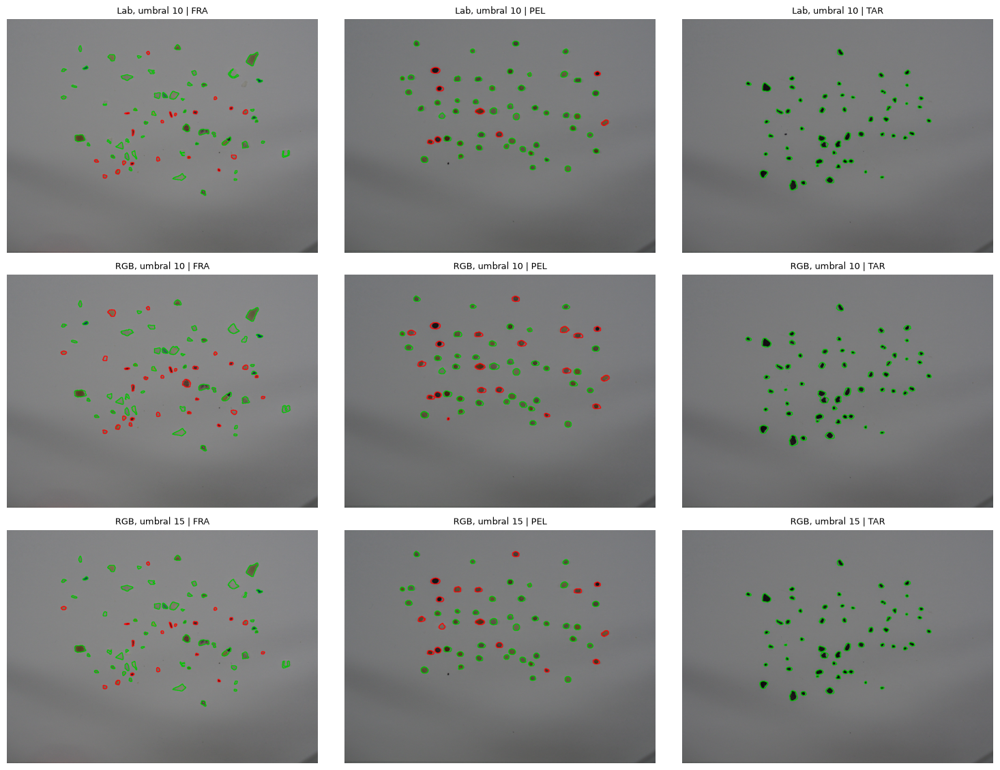

In [10]:
show([renamed(FINAL, "Lab, umbral 10"),
      rules_experiment("RGB, umbral 10", space="rgb"),
      rules_experiment("RGB, umbral 15", space="rgb", threshold=15)])

Se mantiene **Lab**, pues es el que proporciona mejores resultados frente a RGB. La razón de esto es que Lab separa el brillo (L) del color (a, b), por lo que una sombra o un cambio de iluminación afecta principalmente a un canal, mientras que en RGB varían los tres.

#### 2.1.2 Filtros de suavizado

Compara el efecto en la segmentación de aplicar un filtro bilateral, un filtro gaussiano y la imagen sin filtro de suavizado:

          var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
    Bilateral     0.835     413   0.707     328   0.845     309   0.955
Gaussiano 5x5     0.832     417   0.746     330   0.779     315   0.971
Sin suavizado     0.824     422   0.746     330   0.770     318   0.956


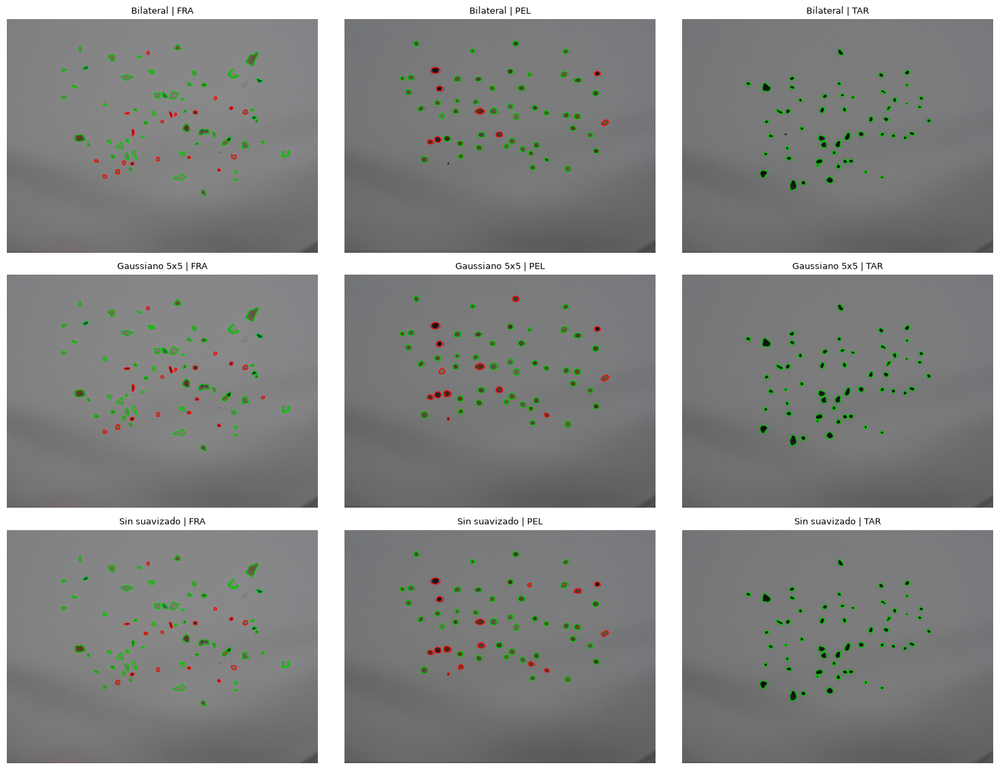

In [11]:
show([renamed(FINAL, "Bilateral"),
      rules_experiment("Gaussiano 5x5", smoothing="gauss"),
      rules_experiment("Sin suavizado", smoothing="none")])

Se elige el **filtro bilateral**, porque reduce el ruido sin difuminar los bordes, útiles pues permiten identificar la forma de la partícula.

#### 2.1.3 Umbrales de separación

Compara distintos umbrales de distancia de color para separar una partícula del fondo:

      var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
 Umbral 6     0.768     423   0.504     325   0.837     306   0.964
Umbral 10     0.835     413   0.707     328   0.845     309   0.955
Umbral 14     0.847     376   0.782     326   0.801     318   0.959
Umbral 18     0.849     326   0.794     323   0.762     317   0.991


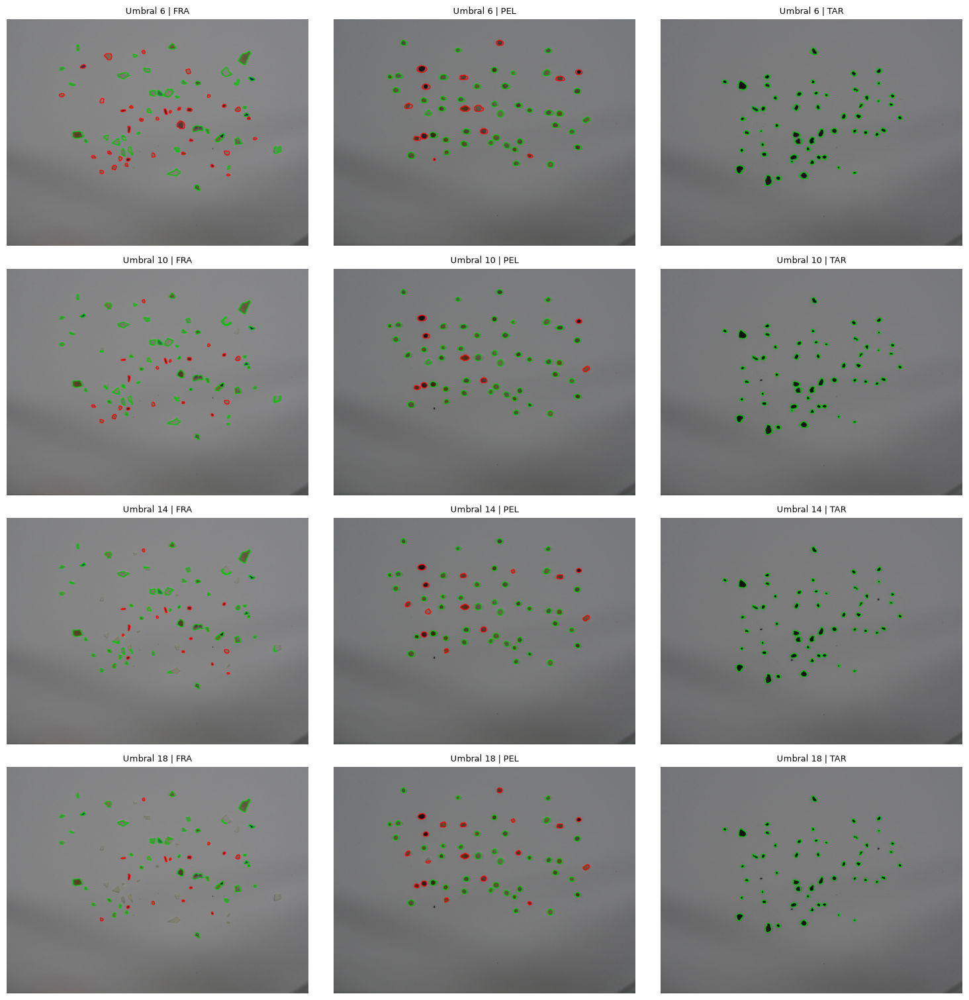

In [12]:
show([rules_experiment(f"Umbral {t}", threshold=t) if t != 10 else renamed(FINAL, "Umbral 10") for t in (6, 10, 14, 18)])

Se elige el umbral **10**. Con umbrales mayores el acierto sube ligeramente, pero se dejan de detectar los fragmentos más claros (413 -> 376 -> 326). Con umbrales menores se detectan más contornos, pero cae el rendimiento del método, al segmentar también sombras y destellos.

#### 2.1.4 Umbral adaptativo

Compara el [umbralizado en Lab](#213-umbrales-de-separación) con el umbral adaptativo gaussiano:

                       var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
 Distancia de color en Lab     0.835     413   0.707     328   0.845     309   0.955
Adaptativo, bloque 11, C=2     0.891     421   0.872     324   0.806     306   0.997
Adaptativo, bloque 31, C=3     0.836     446   0.834     330   0.730     322   0.944


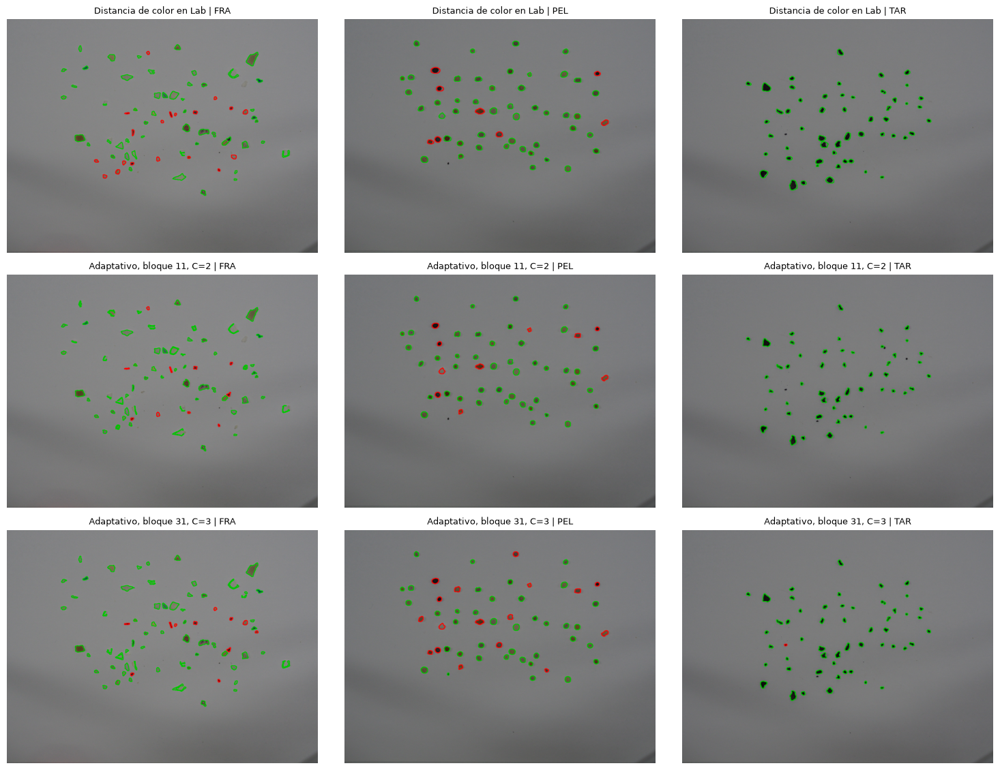

In [13]:
def adaptive_mask(img, block=11, C=2):
    gray = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    return 255 - cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, block, C)

show([renamed(FINAL, "Distancia de color en Lab"),
      rules_experiment("Adaptativo, bloque 11, C=2", mask_fn=adaptive_mask, block=11, C=2),
      rules_experiment("Adaptativo, bloque 31, C=3", mask_fn=adaptive_mask, block=31, C=3)])

El umbral adaptativo con bloque 11 obtiene mejor acierto general, pero la mayor mejora ocurre en la clasificación de los fragmentos. Los valores de acierto son mejores en las clases minoritarias al usar el **umbral de Lab**, por lo que se mantiene este último método en el _pipeline_. Además, el umbral adaptativo solo detecta una partícula si es más oscura que su vecindad, por lo que podría no detectar partículas más claras que el fondo y deformar el contorno de las partículas.

#### 2.1.5 Margen en los bordes

Compara descartar o no las partículas cercanas al borde de la imagen:

       var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
Margen 2 %     0.835     413   0.707     328   0.845     309   0.955
Sin margen     0.835     413   0.707     328   0.845     309   0.955


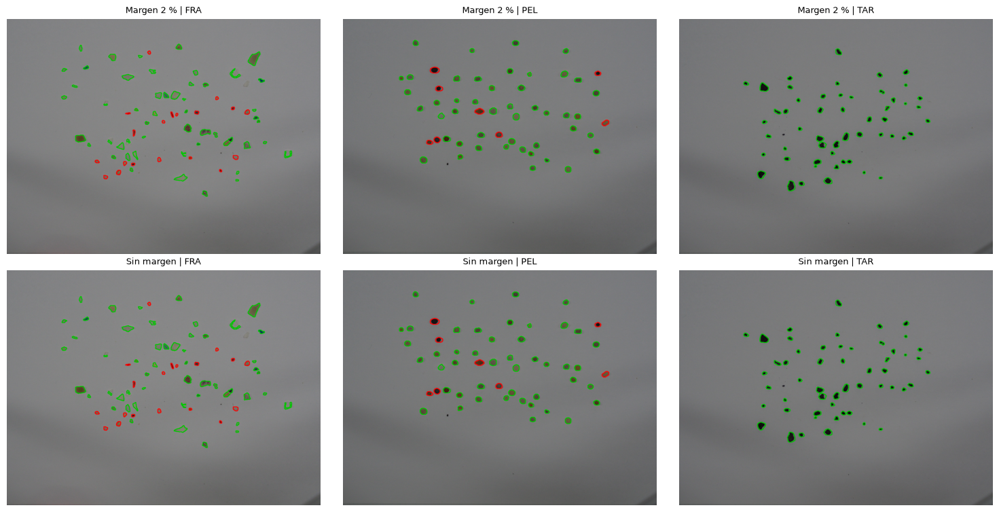

In [14]:
show([renamed(FINAL, "Margen 2 %"), rules_experiment("Sin margen", border=0.0)])

En estas imágenes no hay diferencia, ya que ninguna partícula queda junto al borde. Aun así, se mantiene el margen del 2 %, al ser una práctica habitual en el conteo de partículas. De no añadir margen, las partículas cortadas por el borde tendrían una forma incorrecta y las sombras de las esquinas podrían detectarse como partículas.

#### 2.1.6 Fondo con mediana o gaussiano

Compara la estimación del fondo con un _blur_ mediano o gaussiano:

              var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
Fondo con mediana     0.835     413   0.707     328   0.845     309   0.955
  Fondo gaussiano     0.779     423   0.809     320   0.797     328   0.732


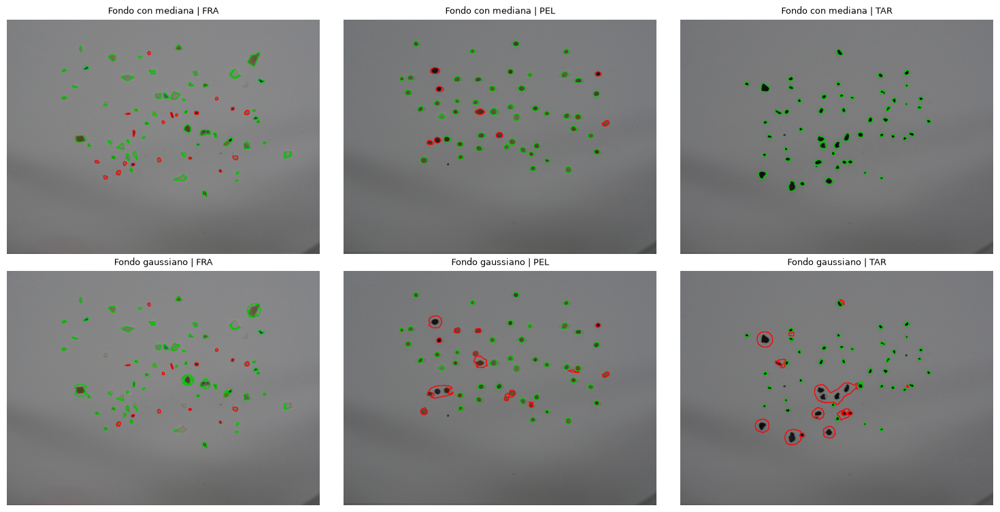

In [15]:
show([renamed(FINAL, "Fondo con mediana"), rules_experiment("Fondo gaussiano", background="gauss")])

La mediana es más eficaz, pues con un tamaño de ventana tan grande (como es 101x101) ignora las partículas y solo mantiene el fondo. El suavizado gaussiano sigue oscureciéndose cerca de las partículas, lo que reduce su distancia al fondo.

#### 2.1.7 Reducir las fotos de entrenamiento (`SCALE_TRAIN`)

Las fotos de entrenamiento (cámara) tienen mucha más resolución que la imagen de _test_ (escáner). Se compara reducirlas al 25 % con usarlas a resolución completa:

                var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
  Reducidas al 25 %     0.860     210   0.757     164   0.841     156   0.981
Resolución completa     0.822     305   0.797     170   0.776     189   0.894


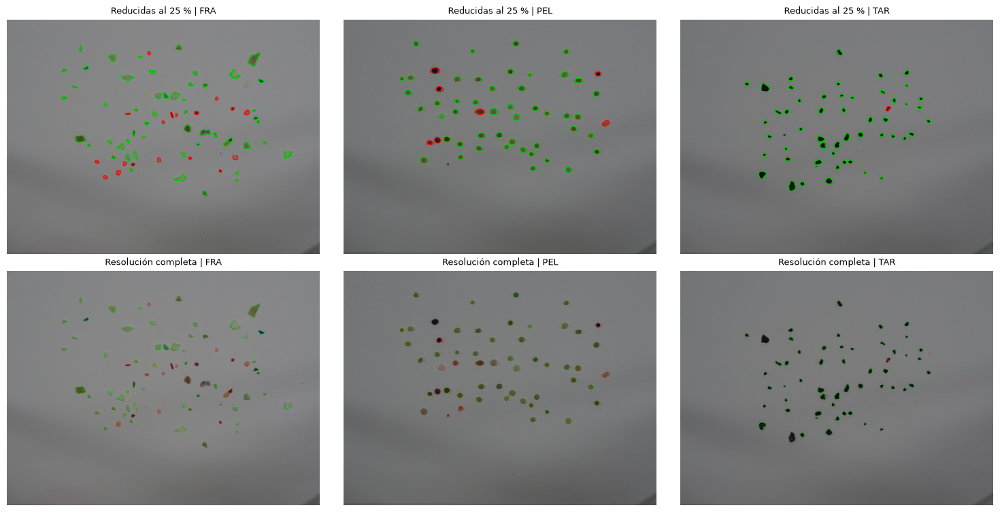

In [16]:
show([rules_experiment("Reducidas al 25 %", images=make_train_set(scale=0.25, n_aug=2)),
      rules_experiment("Resolución completa", images=make_train_set(scale=1.0, n_aug=2))])

Se mantiene la reducción al **25 %**, al tener un acierto mayor con un tiempo de ejecución mucho menor.

### 2.2 Características de las partículas

#### 2.2.1 Características geométricas de SMACC

Se evalúa cada característica geométrica de SMACC para distinguir _pellets_ de fragmentos. Como medida adicional se usa el AUC, que indica lo bien que discrimina una característica entre las clases. No se prueban el área ni el perímetro en píxeles, porque dependen de la escala de la imagen:

In [17]:
SHAPE_THRESHOLDS = {
    "circularity": np.arange(0.70, 0.93, 0.01),
    "dist_ratio": np.arange(0.30, 0.90, 0.02),
    "area_bbox_ratio": np.arange(0.50, 0.90, 0.02),
    "ellipse_ratio": np.arange(0.50, 0.95, 0.02),
    "aspect_ratio": np.arange(0.40, 0.98, 0.02),
}

plastic = FINAL["df"][FINAL["df"]["label"] != "TAR"]
auc = {shape: roc_auc_score(plastic["label"] == "PEL", plastic[shape]) for shape in SHAPE_THRESHOLDS}
pd.Series(auc, name="AUC PEL vs FRA").round(3)

circularity        0.902
dist_ratio         0.944
area_bbox_ratio    0.917
ellipse_ratio      0.850
aspect_ratio       0.653
Name: AUC PEL vs FRA, dtype: float64

                            var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
    Características circularity     0.835     413   0.707     328   0.845     309   0.955
     Características dist_ratio     0.854     413   0.860     328   0.747     309   0.955
Características area_bbox_ratio     0.841     413   0.787     328   0.747     309   0.990
  Características ellipse_ratio     0.799     413   0.729     328   0.704     309   0.964
   Características aspect_ratio     0.729     413   0.460     328   0.762     309   0.964


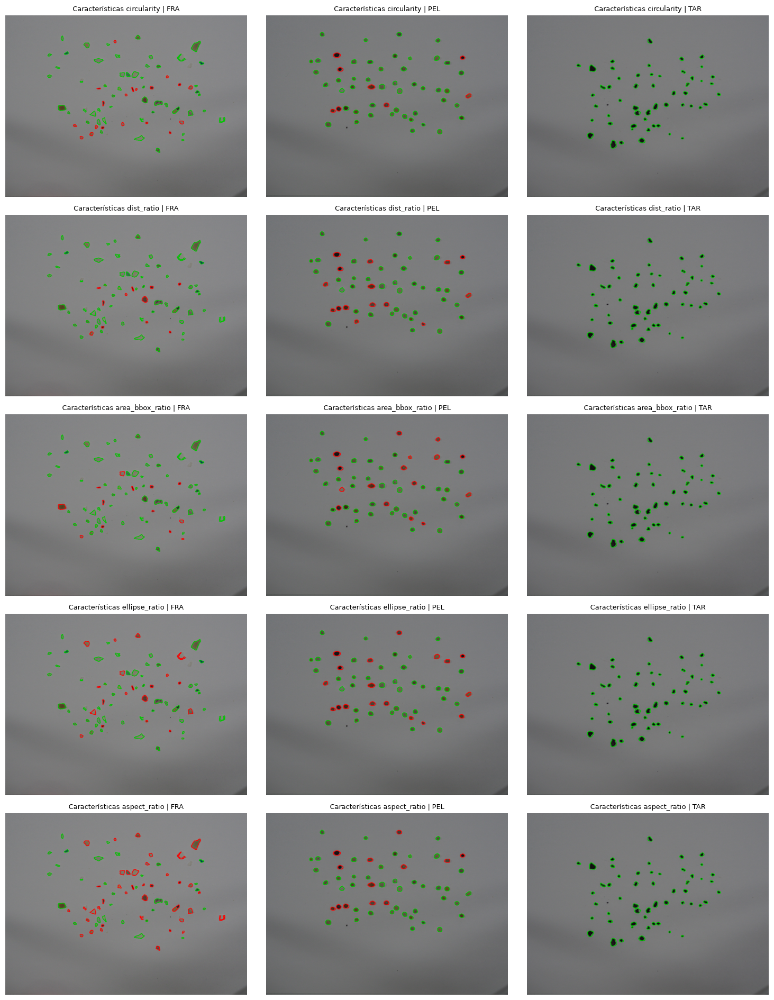

In [18]:
def predict_by_shape(df, t):
    is_tar = (df["L_ratio"] < t["max_brightness"]) & (df["chroma_rel"] < t["max_color"])
    is_pel = df[t["shape"]] > t["min_roundness"]
    return np.select([is_tar, is_pel], ["TAR", "PEL"], default="FRA")

def shape_possibilities(shape):
    return {"max_brightness": THRESHOLD_POSSIBILITIES["max_brightness"],
            "max_color": THRESHOLD_POSSIBILITIES["max_color"],
            "shape": [shape],
            "min_roundness": SHAPE_THRESHOLDS[shape]}

show([rules_experiment(f"Características {shape}", predict_fn=predict_by_shape,
                       possibilities=shape_possibilities(shape))
      for shape in SHAPE_THRESHOLDS])

`dist_ratio` y `area_bbox_ratio` obtienen los mejores aciertos. No obstante, se utiliza la **circularidad**, al no existir mucha diferencia de acierto, y al tratarse de una característica sencilla que por sí sola diferencia en gran medida los _pellets_ de los fragmentos.

#### 2.2.2 Detección de TAR

Tras algunos experimentos utilizando únicamente la componente L (luminosidad) para detectar TAR, no se estaban obteniendo resultados muy precisos. Esto ha motivado la búsqueda de nuevas heurísticas para la detección de este tipo de partículas. La más relevante es la inclusión de la tonalidad de la partícula:

                var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
Luminosidad y color     0.835     413   0.707     328   0.845     309   0.955
   Solo luminosidad     0.793     413   0.755     328   0.750     309   0.874
         Solo color     0.787     413   0.663     328   0.805     309   0.893


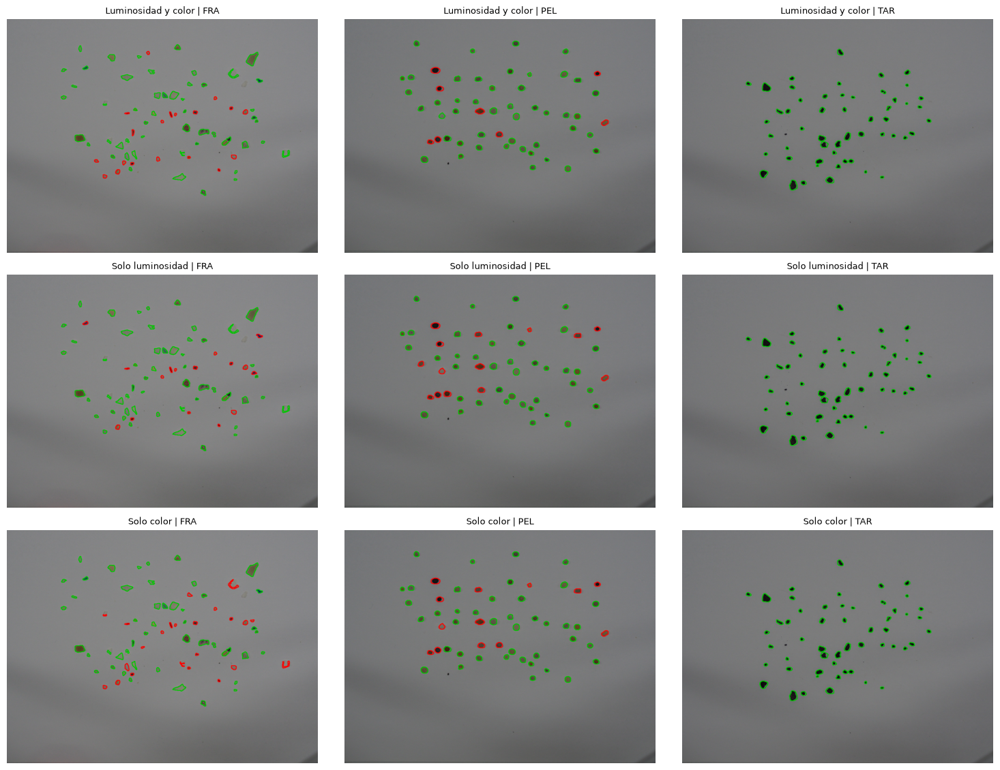

In [19]:
def predict_only_dark(df, t):
    is_tar = df["L_ratio"] < t["max_brightness"]
    is_pel = df["circularity"] > t["min_circularity"]
    return np.select([is_tar, is_pel], ["TAR", "PEL"], default="FRA")

def predict_only_colorless(df, t):
    is_tar = df["chroma_rel"] < t["max_color"]
    is_pel = df["circularity"] > t["min_circularity"]
    return np.select([is_tar, is_pel], ["TAR", "PEL"], default="FRA")

ONLY_DARK = {"max_brightness": THRESHOLD_POSSIBILITIES["max_brightness"],
             "min_circularity": THRESHOLD_POSSIBILITIES["min_circularity"]}
ONLY_COLORLESS = {"max_color": THRESHOLD_POSSIBILITIES["max_color"],
                  "min_circularity": THRESHOLD_POSSIBILITIES["min_circularity"]}

show([renamed(FINAL, "Luminosidad y color"),
      rules_experiment("Solo luminosidad", predict_fn=predict_only_dark, possibilities=ONLY_DARK),
      rules_experiment("Solo color", predict_fn=predict_only_colorless, possibilities=ONLY_COLORLESS)])

La combinación de luminosidad y color permite mejorar la detección. La luminosidad descarta partículas muy claras, y el color impide que se detecten fragmentos oscuros de distintas tonalidades (por ejemplo, _pellets_ marrones o fragmentos azul oscuro).

#### 2.2.3 Detección de textura

Evalúa la eficacia de añadir textura para detectar TAR. En este caso, se define la textura según la variación del brillo en la partícula. Nuevamente, se añade AUC para determinar la eficacia de añadir esta medida:

In [20]:
def texture(c, img):
    mask = np.zeros(img.shape[:2], np.uint8)
    cv2.drawContours(mask, [c], -1, 255, -1)
    inside = mask > 0

    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[inside]
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[inside]
    bgr = img[inside]

    return {"L_std": lab[:, 0].std(),
            "H_std": hsv[:, 0].std(),
            "V_std": hsv[:, 2].std(),
            "RGB_std": bgr.std(axis=0).mean()}

NO_TEXTURE = rules_experiment("Sin textura", extra=texture)
df = NO_TEXTURE["df"]
auc = {f: roc_auc_score(df["label"] == "TAR", df[f]) for f in ["L_std", "H_std", "V_std", "RGB_std"]}
pd.Series(auc, name="AUC TAR vs resto").round(3)

L_std      0.959
H_std      0.675
V_std      0.954
RGB_std    0.953
Name: AUC TAR vs resto, dtype: float64

                         var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
                 Sin textura     0.835     413   0.707     328   0.845     309   0.955
Luminosidad, color y textura     0.854     413   0.702     328   0.869     309   0.990
       Luminosidad y textura     0.838     413   0.753     328   0.771     309   0.990


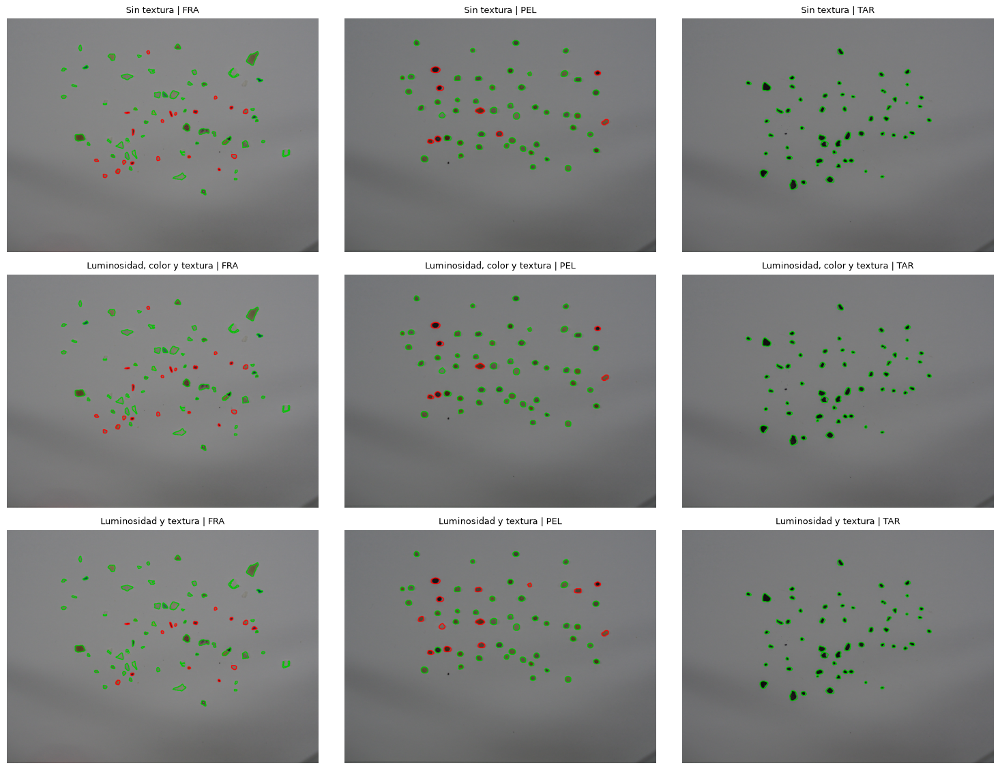

In [21]:
def predict_with_texture(df, t):
    is_tar = (df["L_ratio"] < t["max_brightness"]) & (df["chroma_rel"] < t["max_color"]) & (df["L_std"] > t["min_texture"])
    is_pel = df["circularity"] > t["min_circularity"]
    return np.select([is_tar, is_pel], ["TAR", "PEL"], default="FRA")

TEXTURE_POSSIBILITIES = {**THRESHOLD_POSSIBILITIES, "min_texture": np.arange(8, 40, 2.0)}
TEXTURE_NO_COLOR = {**TEXTURE_POSSIBILITIES, "max_color": [np.inf]}

show([NO_TEXTURE,
      rules_experiment("Luminosidad, color y textura", extra=texture,
                       predict_fn=predict_with_texture, possibilities=TEXTURE_POSSIBILITIES),
      rules_experiment("Luminosidad y textura", extra=texture,
                       predict_fn=predict_with_texture, possibilities=TEXTURE_NO_COLOR)])

Añadir la textura mejora la detección del alquitrán en estas imágenes, pero el aumento en el acierto es muy leve. Además, la variación de brillo dentro de una partícula depende mucho de la resolución, el enfoque y el ruido, por lo que el umbral _aprendido_ podría no mantenerse en distintas imágenes. Es por ello que no se incluye la detección de textura en el _pipeline_.

#### 2.2.4 Detección de textura LBP

También se ha evaluado la textura con el método LBP, utilizado en el proyecto SMACC. Al necesitar un clasificador, se ha utilizado KNN por su sencillez para probar el método de forma rápida:

In [22]:
def lbp_histogram(c, img):
    mask = np.zeros(img.shape[:2], np.uint8)
    cv2.drawContours(mask, [c], -1, 255, -1)

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    codes = local_binary_pattern(gray, P=8, R=1, method="uniform")[mask > 0]
    hist = np.bincount(codes.astype(int), minlength=10) / len(codes)
    return {f"lbp{i}": v for i, v in enumerate(hist)}

LBP = [f"lbp{i}" for i in range(10)]
OURS = ["circularity", "L_ratio", "chroma_rel"]
originals = {label: images[:1] for label, images in TRAIN_SET.items()}
lbp_df = particle_table(originals, extra=lbp_histogram)

                                var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
     Reglas (solo fotos originales)     0.872      70   0.729      54   0.889      51   1.000
                       k-NN con LBP     0.754      70   0.657      54   0.741      51   0.863
k-NN con nuestras 3 características     0.873      70   0.786      54   0.852      51   0.980
               k-NN con las 3 + LBP     0.825      70   0.643      54   0.852      51   0.980


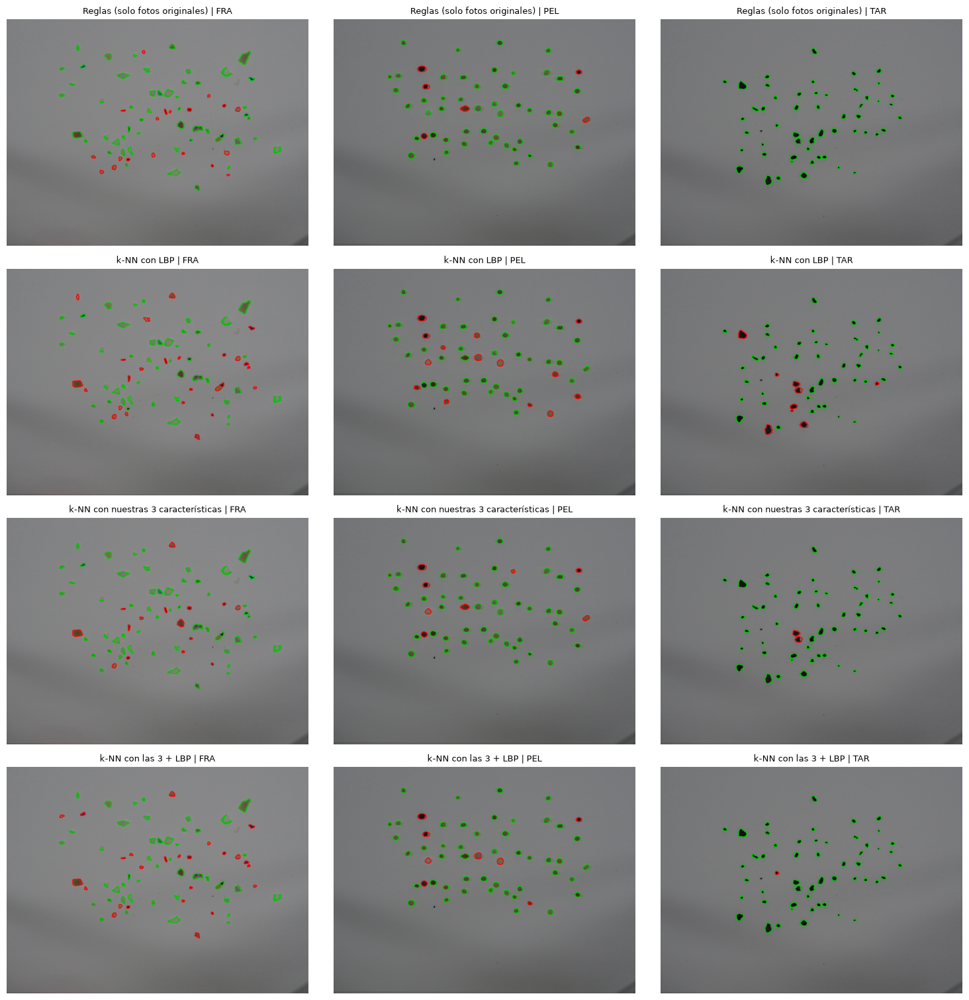

In [23]:
def knn_experiment(name, columns):
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    y_pred = cross_val_predict(knn, lbp_df[columns], lbp_df.label, cv=LeaveOneOut())
    return result(name, lbp_df, y_pred)

show([rules_experiment("Reglas (solo fotos originales)", images=originals),
      knn_experiment("k-NN con LBP", LBP),
      knn_experiment("k-NN con nuestras 3 características", OURS),
      knn_experiment("k-NN con las 3 + LBP", OURS + LBP)])

LBP no mejora el rendimiento en este caso, por lo que se descarta su uso para este problema.

#### 2.2.5 `cv2.matchShapes`

Verifica la eficacia de clasificar las partículas por forma utilizando la similitud de los contornos (`cv2.matchShapes`):

                           var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
Reglas (solo fotos originales)     0.872      70   0.729      54   0.889      51    1.00
          1-NN con matchShapes     0.459      70   0.200      54   0.667      51    0.51


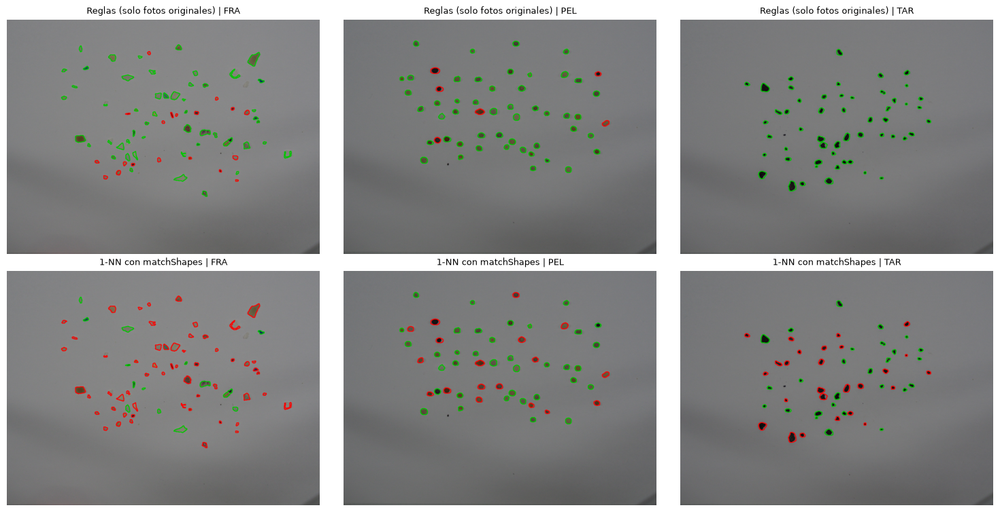

In [24]:
df = particle_table(originals)
contours = list(df.contour)
nearest = []
for i, c in enumerate(contours):
    distances = [cv2.matchShapes(c, other, cv2.CONTOURS_MATCH_I2, 0) if j != i else 99999
                 for j, other in enumerate(contours)]
    nearest.append(df.label.iloc[int(np.argmin(distances))])

show([rules_experiment("Reglas (solo fotos originales)", images=originals),
      result("1-NN con matchShapes", df, np.array(nearest))])

`matchShapes` no es eficaz (acierto de 0,459): la única clase con una forma característica y homogénea son los _pellets_, para los que ya se usa la circularidad, mientras que los fragmentos y el alquitrán tienen formas muy variadas. Se descarta su uso por esta razón.

### 2.3 Datos de entrenamiento

#### 2.3.1 _Data augmentation_

Compara utilizar o no _data augmentation_ para aumentar el conjunto de datos de entrada:

                  var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
Con data augmentation     0.835     413   0.707     328   0.845     309   0.955
      Solo originales     0.733     413   0.688     328   0.915     309   0.595


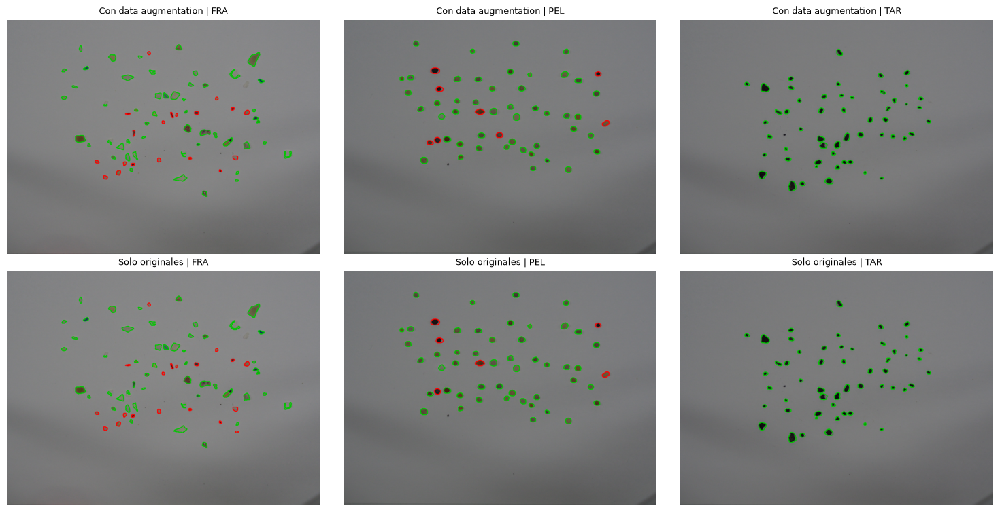

In [25]:
show([renamed(FINAL, "Con data augmentation"), rules_experiment("Solo originales", images=originals, measure_on=TRAIN_SET)])

Se mantiene el uso de _data augmentation_, al mejorar considerablemente el acierto. Sin él, los umbrales elegidos solo con las fotos originales fallan cuando se cambia la iluminación, el color o la nitidez de la imagen.

#### 2.3.2 Reescalado como _data augmentation_

Evalúa la eficacia de añadir un factor de escala adicional a modo de _data augmentation_:

                   var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
        Sin reescalado     0.835     413   0.707     328   0.845     309   0.955
Aumento con reescalado     0.832     413   0.775     328   0.756     309   0.964


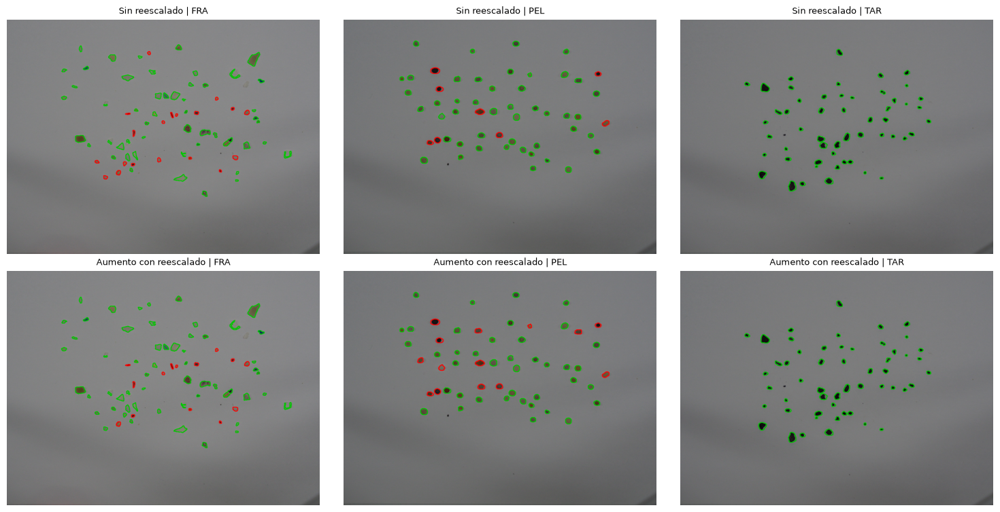

In [26]:
np.random.seed(1)
rescaled = {}
for label, path in TRAIN.items():
    full = cv2.imread(path)
    versions = [load(path)]
    for _ in range(5):
        s = np.random.uniform(0.20, 0.30)
        versions.append(augment(cv2.resize(full, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)))
    rescaled[label] = versions

show([renamed(FINAL, "Sin reescalado"), rules_experiment("Aumento con reescalado", images=rescaled, measure_on=TRAIN_SET)])

Se descarta el reescalado, al no mejorar el resultado. La mejora del acierto con el reescalado se produce al reducir la imagen original con `SCALE_TRAIN`. Añadir escalas aleatorias no aporta ninguna mejora.

### 2.4 Clasificador

#### 2.4.1 Orden de las reglas

Compara comprobar primero si la partícula es alquitrán y después si es redonda, o al revés:

                 var  accuracy  detFRA  accFRA  detPEL  accPEL  detTAR  accTAR
Alquitrán -> Redondo     0.835     413   0.707     328   0.845     309   0.955
Redondo -> Alquitrán     0.726     413   0.833     328   0.671     309   0.673


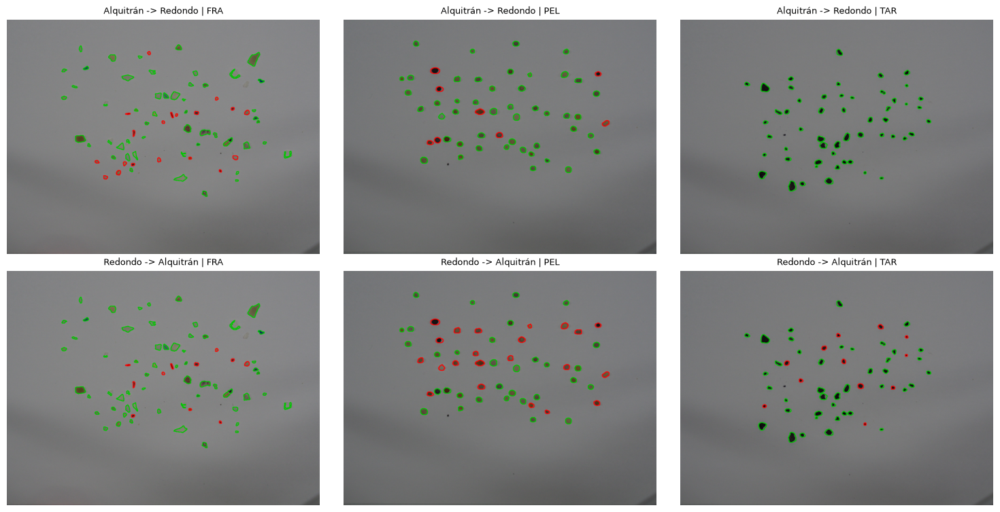

In [27]:
def predict_pellet_first(df, t):
    is_tar = (df["L_ratio"] < t["max_brightness"]) & (df["chroma_rel"] < t["max_color"])
    is_pel = df["circularity"] > t["min_circularity"]
    return np.select([is_pel, is_tar], ["PEL", "TAR"], default="FRA")

show([renamed(FINAL, "Alquitrán -> Redondo"), rules_experiment("Redondo -> Alquitrán", predict_fn=predict_pellet_first)])

Algunas partículas de TAR también son bastante redondas, por lo que empezar por la detección de luminosidad/color permite discriminar más precisamente las partículas de TAR del resto.